# Many-body entanglement quantification through a few partial-transpose moments

Code and data for the Letter *"Many-body entanglement quantification in
arbitrary states through a few partial-transpose moments"* by
S. Chakrabarty and A. S. Majumdar, and its Supplemental Material (SM).

The notebook reproduces every number, table and figure of the Letter, the
End Matter and the SM. It runs from top to bottom without manual steps
(about 25 minutes on a laptop, most of it in the DMRG and linear-programming
sections). Figures are written to `./figures/` as PDF and PNG, and the data
behind them to `./figures/*.json` and `*.npz`. The last section compares
every number quoted in the manuscript with the computed value.

**Contents**

1. Closed-form quantifiers $\mathcal E_4$, $\mathcal E_6$, $\mathcal E_8$ (Eqs. (10)-(13))
2. General solvers for any even order $K$ (Theorem 1, SM Sec. S7)
3. Two-qubit benchmarks (Fig. 1)
4. Many-body ground states: TFIM, XXZ chain, LMG model (Fig. 2)
5. Thermal state (Fig. 3)
6. High orders, two-qubit states (End Matter, Fig. 4)
7. High orders, many-body states (End Matter, Fig. 5)
8. Finite statistics (End Matter, Fig. 6)
9. DMRG beyond exact diagonalization (End Matter, Fig. 7)
10. Bounds from all moments, certified by linear programming (SM Sec. S8, Table S1, Fig. S1)
11. Small windows (SM Sec. S9, Fig. S2)
12. A bound at a stated confidence (SM Sec. S10, Fig. S3)
13. Stabilizer states, pure and mixed (Corollary 1, SM Sec. S4)
14. Every number quoted in the manuscript, checked

**Conventions used throughout**

* Moments $p_k=\mathrm{tr}[(\rho^\Gamma)^k]$ and reduced moments $\mu_k=p_{2k}/p_2^k$.
* Many-body geometry: open chain of $n$ sites, blocks $A$ and $B$ of five
  adjacent sites in the middle, the remaining sites $C$ split equally between
  the two ends and traced out. For $n=12$ this is $C=\{0,11\}$,
  $A=\{1,\dots,5\}$, $B=\{6,\dots,10\}$. The same function `window(n)` is used
  for exact diagonalization, the high-order scans and DMRG.
* Ground states are computed in a fixed symmetry sector, so that they are
  unique also where the spectrum is (quasi-)degenerate: even parity
  $\prod_k\sigma^z_k=+1$ for the TFIM and the LMG model, total magnetization
  $\sum_k\sigma^z_k=0$ for the XXZ chain.
* High orders are evaluated in two independent ways: the Lanczos
  (Stieltjes) construction of the quadrature rule from the spectrum in
  80-digit arithmetic, and the moment-only route through the Hankel system.
* Bounds from all moments are certified by the dual of the linear program,
  verified in exact rational arithmetic.

Set the environment variable `REUSE_DMRG=1` to load the DMRG results from
`figures/dmrg_results.json` instead of recomputing them.

In [1]:
import os, json, time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq, minimize_scalar
import mpmath as mp
import matplotlib
import matplotlib.pyplot as plt

FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)
SEED = 20260923

# ---------------------------------------------------------------- style
# Sizes are the printed sizes: single column 3.4 in, double column 7.0 in.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8.5, "axes.labelsize": 9.5, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "lines.linewidth": 1.3, "lines.markersize": 4.0, "lines.markeredgewidth": 0.9,
    "axes.linewidth": 0.7,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 3.0, "ytick.major.size": 3.0,
    "xtick.minor.size": 1.6, "ytick.minor.size": 1.6,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "axes.grid": True, "grid.color": "0.85", "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "legend.frameon": True, "legend.framealpha": 1.0, "legend.fancybox": False,
    "legend.edgecolor": "black", "legend.borderpad": 0.4,
    "legend.handlelength": 2.2, "legend.labelspacing": 0.3,
    "pdf.fonttype": 42, "figure.dpi": 150, "savefig.dpi": 400,
})

# One color/marker code for E, E4, E6, E8 in every figure.
COL = {"E": "black", "E4": "#1f4fd1", "E6": "#1a9e3a", "E8": "#d62728"}
STYLE = {
    "E":  dict(color=COL["E"],  ls="-",  marker="*", label=r"$\mathcal{E}$ (Exact)", zorder=5),
    "E4": dict(color=COL["E4"], ls="--", marker="o", label=r"$\mathcal{E}_4$", zorder=4),
    "E6": dict(color=COL["E6"], ls=":",  marker="^", label=r"$\mathcal{E}_6$", zorder=4),
    "E8": dict(color=COL["E8"], ls="-.", marker="s", label=r"$\mathcal{E}_8$", zorder=4),
}
KEYS = ("E", "E4", "E6", "E8")

def plot_q(ax, x, y, k, every=1, **kw):
    st = dict(STYLE[k]); st.update(kw)
    ax.plot(x, y, markevery=every, markerfacecolor="none",
            markeredgecolor=st["color"], **st)

def panel_label(ax, s, x=0.04, y=0.95, ha="left", va="top"):
    ax.text(x, y, s, transform=ax.transAxes, ha=ha, va=va, fontsize=9.5,
            bbox=dict(fc="white", ec="none", pad=0.6), zorder=10)

def save(fig, name):
    fig.savefig(f"{FIGDIR}/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(f"{FIGDIR}/{name}.png", bbox_inches="tight", pad_inches=0.02)

## 1. Closed-form quantifiers $\mathcal E_4,\mathcal E_6,\mathcal E_8$ (main text Eqs. (10)-(13), SM Sec. S3)

$\mathcal E_4$ is the one-point Gauss rule, $\mathcal E_6$ the Gauss-Radau rule
with one free node and one node at $x=1$, $\mathcal E_8$ the two-point Gauss
rule. If the spectrum has a single nonzero magnitude ($\mu_3=\mu_2^2$), all
three equal $\mathcal E$ (Theorem 2) and the formulas fall back to $\mathcal E_4$.
The degeneracy test uses a relative tolerance.

In [2]:
REL_TOL = 1e-10

def moments(lam, kmax=4):
    lam = np.asarray(lam, dtype=float)
    return {2 * k: float(np.sum(lam ** (2 * k))) for k in range(1, kmax + 1)}

def exact_E(lam):
    return float(np.log(np.sum(np.abs(lam))))

def E4_q(p2, p4):
    return 1.5 * np.log(p2) - 0.5 * np.log(p4)

def E6_q(p2, p4, p6):
    mu2, mu3 = p4 / p2**2, p6 / p2**3
    if mu3 - mu2**2 <= REL_TOL * mu2**2:          # single magnitude
        return E4_q(p2, p4)
    a = (mu2 - mu3) / (1 - mu2)
    wa = (1 - mu2)**2 / (1 - 2 * mu2 + mu3)
    return 0.5 * np.log(p2) + np.log(wa / np.sqrt(a) + 1 - wa)

def E8_q(p2, p4, p6, p8):
    mu2, mu3, mu4 = p4 / p2**2, p6 / p2**3, p8 / p2**4
    if mu3 - mu2**2 <= REL_TOL * mu2**2:          # single magnitude
        return E4_q(p2, p4)
    alpha = (mu4 - mu2 * mu3) / (mu3 - mu2**2)
    beta = alpha * mu2 - mu3
    r = np.sqrt(max(alpha**2 - 4 * beta, 0.0))
    x1, x2 = (alpha + r) / 2, (alpha - r) / 2
    if r <= REL_TOL * alpha:                      # nodes merge: one-point rule
        return 0.5 * np.log(p2) - 0.5 * np.log(x1)
    w1 = (mu2 - x2) / (x1 - x2)
    return 0.5 * np.log(p2) + np.log(w1 / np.sqrt(x1) + (1 - w1) / np.sqrt(x2))

def all_quantifiers(lam):
    m = moments(lam)
    return (exact_E(lam), E4_q(m[2], m[4]), E6_q(m[2], m[4], m[6]),
            E8_q(m[2], m[4], m[6], m[8]))

## 2. General solvers for any even $K$ (Theorem 1, SM Sec. S7)

For $r=K/2$ given moments the minimizer is the $\ell$-point Gauss rule
($r$ even) or the Gauss-Radau rule with $\ell$ free nodes and one node at
$x=1$ ($r$ odd), $\ell=\lfloor K/4\rfloor$. The orthogonal polynomial is
obtained from the Hankel system, the weights from the Vandermonde system, in
100-digit arithmetic. `check_rule` verifies that the rule is a valid
quadrature: real nodes in $(0,1)$, positive weights, and all given moments
reproduced. This is the route available from measured moments, and it
becomes ill-conditioned at high order.

For a known spectrum, `SpectrumRules` builds the same rules directly from
the measure $\nu$ by the Lanczos (Stieltjes) procedure, which is stable at
any order and also detects when $\nu$ has fewer points than the rule
($s\le\ell$), in which case $\mathcal E_K=\mathcal E$ exactly (Theorem 2).

In [3]:
mp.mp.dps = 100

def gauss_or_radau(mom):
    # mom = [mu_1=1, mu_2, ..., mu_r] as mpf. Returns nodes, weights.
    r = len(mom)
    if r % 2 == 0:
        ell = r // 2
        base, fixed = mom, []
    else:
        ell = (r - 1) // 2
        base, fixed = [mom[j] - mom[j + 1] for j in range(r - 1)], [mp.mpf(1)]
    if ell > 0:
        H = mp.matrix(ell, ell); rhs = mp.matrix(ell, 1)
        for i in range(ell):
            for j in range(ell):
                H[i, j] = base[i + j]
            rhs[i] = -base[i + ell]
        c = mp.lu_solve(H, rhs)
        poly = [mp.mpf(1)] + [c[ell - 1 - k] for k in range(ell)]
        roots = mp.polyroots(poly, maxsteps=800, extraprec=800)
        if max(abs(mp.im(z)) for z in roots) > mp.mpf(10) ** (-40):
            raise ValueError("complex nodes")
        nodes = sorted(mp.re(z) for z in roots) + fixed
    else:
        nodes = fixed
    m = len(nodes)
    V = mp.matrix(m, m); rhs = mp.matrix(m, 1)
    for i in range(m):
        for j in range(m):
            V[i, j] = nodes[j] ** i
        rhs[i] = mom[i]
    w = mp.lu_solve(V, rhs)
    return nodes, [w[j] for j in range(m)]

def check_rule(nodes, weights, mom, tol=mp.mpf(10) ** (-30)):
    if any(x <= 0 or x > 1 for x in nodes) or any(w <= 0 for w in weights):
        return False
    for k, mk in enumerate(mom):
        if abs(sum(w * x**k for x, w in zip(nodes, weights)) - mk) > tol * abs(mk):
            return False
    return True

def E_K_hankel(p2, mu, K):
    # Moment-only route: p2 and mu = {k: mu_k} as mpf; returns E_K (or raises).
    r = K // 2
    mom = [mp.mpf(1)] + [mu[k] for k in range(2, r + 1)]
    nodes, weights = gauss_or_radau(mom)
    if not check_rule(nodes, weights, mom):
        raise ValueError("invalid rule")
    S = sum(w / mp.sqrt(x) for x, w in zip(nodes, weights))
    return mp.log(p2) / 2 + mp.log(S)


class SpectrumRules:
    # Gauss / Gauss-Radau rules of the measure nu of a given PT spectrum,
    # built by the Lanczos (Stieltjes) procedure with full
    # reorthogonalization in 80-digit arithmetic. This needs no moments and
    # is stable at any order; it is used to evaluate E_K for known spectra.
    def __init__(self, lam, m_max, dps=80):
        self.dps = dps
        with mp.workdps(dps):
            lm = [mp.mpf(float(x)) for x in lam if x != 0]
            self.E = mp.log(sum(abs(x) for x in lm))
            self.p2 = sum(x * x for x in lm)
            q = np.array([x * x / self.p2 for x in lm], dtype=object)
            v = np.array([mp.sqrt(t) for t in q], dtype=object)     # weights of nu are q_i
            V, a, b = [v], [], []
            for k in range(m_max):
                u = q * V[-1]
                a.append(np.dot(V[-1], u))
                u = u - a[-1] * V[-1] - (b[-1] * V[-2] if k > 0 else 0)
                for _ in range(2):
                    for w in V:
                        u = u - np.dot(w, u) * w
                bk = mp.sqrt(np.dot(u, u))
                b.append(bk)
                if bk < mp.mpf(10) ** (-(dps - 20)):
                    break                       # Krylov space exhausted: nu has len(a) points
                V.append(u / bk)
            self.a, self.b = a, b
            self.n_points = len(a) if b[-1] < mp.mpf(10) ** (-(dps - 20)) else None

    def E_K(self, K):
        r = K // 2
        even = (r % 2 == 0)
        ell = r // 2 if even else (r - 1) // 2
        m = ell if even else ell + 1
        with mp.workdps(self.dps):
            if self.n_points is not None and ell >= self.n_points:
                return self.E                   # s <= ell: the rule is nu itself
            if len(self.a) < m:
                raise ValueError("increase m_max")
            J = mp.matrix(m, m)
            for i in range(ell):
                J[i, i] = self.a[i]
                if i < ell - 1:
                    J[i, i + 1] = J[i + 1, i] = self.b[i]
            if not even:                        # Gauss-Radau: node fixed at x = 1
                if ell > 0:
                    M = J[0:ell, 0:ell] - mp.eye(ell)
                    e = mp.matrix(ell, 1); e[ell - 1] = self.b[ell - 1] ** 2
                    d = mp.lu_solve(M, e)
                    J[ell, ell] = 1 + d[ell - 1]
                    J[ell, ell - 1] = J[ell - 1, ell] = self.b[ell - 1]
                else:
                    J[0, 0] = 1
            th, U = mp.eigsy(J)
            nodes = [th[j] for j in range(m)]
            weights = [U[0, j] ** 2 for j in range(m)]
            if any(x <= 0 or x > 1 + mp.mpf(10) ** (-40) for x in nodes) or any(w <= 0 for w in weights):
                raise ValueError("invalid rule")
            S = sum(w / mp.sqrt(x) for x, w in zip(nodes, weights))
            return mp.log(self.p2) / 2 + mp.log(S)


def K_sweep(lam, K_list, hankel_upto=0, E_tol=1e-12):
    # Primary values from SpectrumRules. The moment-only Hankel route is
    # evaluated for K <= hankel_upto as an independent check; the largest
    # order at which it still passes all checks and the largest deviation
    # from the primary values are returned.
    lam = np.asarray(lam)
    m_max = max(K_list) // 4 + 1
    R = SpectrumRules(lam, m_max)
    Ks, EKs, prev = [], [], -mp.inf
    for K in K_list:
        val = R.E_K(K)
        assert val <= R.E + E_tol and val >= prev - E_tol, f"ordering violated at K={K}"
        Ks.append(K); EKs.append(float(val)); prev = val
    dev, K_hankel = 0.0, None
    if hankel_upto:
        lm = [mp.mpf(float(x)) for x in lam if x != 0]
        p2 = sum(x * x for x in lm)
        q = [x * x / p2 for x in lm]
        for K, v in zip(Ks, EKs):
            if K > hankel_upto:
                break
            try:
                mu = {k: sum(qi**k for qi in q) for k in range(2, K // 2 + 1)}
                vh = float(E_K_hankel(p2, mu, K))
            except Exception:
                break
            if vh > float(R.E) + E_tol:
                break
            dev, K_hankel = max(dev, abs(vh - v)), K
    return float(R.E), Ks, EKs, dict(K_hankel=K_hankel, max_dev=dev, n_points=R.n_points)

def distinct_magnitudes(lam, rel=1e-9, abs_tol=1e-13, zero=1e-12):
    a = np.sort(np.abs(np.asarray(lam)))
    a = a[a > zero]
    s, last = 0, None
    for x in a:
        if last is None or x - last > rel * x + abs_tol:
            s += 1
        last = x
    return s

### Test: closed forms agree with the general solver

In [4]:
rng_t = np.random.default_rng(1)
worst = 0.0
for trial in range(200):
    d = rng_t.integers(3, 40)
    lam = rng_t.normal(size=d) * rng_t.random(d) ** 3
    lam = lam / lam.sum()
    E, E4, E6, E8 = all_quantifiers(lam)
    _, Ks, EKs, info = K_sweep(lam, [4, 6, 8, 10, 12], hankel_upto=12)
    assert info["K_hankel"] == 12 and info["max_dev"] < 1e-20
    worst = max(worst, abs(E4 - EKs[0]), abs(E6 - EKs[1]), abs(E8 - EKs[2]))
    assert E4 <= E6 + 1e-12 <= E8 + 2e-12 <= E + 3e-12
print(f"max |closed form - Lanczos solver| over 200 random spectra: {worst:.2e}")
print("Hankel and Lanczos routes agree to better than 1e-20 up to K=12 on all of them")

max |closed form - Lanczos solver| over 200 random spectra: 3.61e-13
Hankel and Lanczos routes agree to better than 1e-20 up to K=12 on all of them


## 3. Two-qubit benchmarks (main text Fig. 1, Eqs. (16)-(17))

Werner state: PT eigenvalue $(1+p)/4$ three times and $(1-3p)/4$ once.
Pure state $\alpha|00\rangle+\sqrt{1-\alpha^2}|11\rangle$: PT eigenvalues
$\alpha^2$, $1-\alpha^2$, $\pm\alpha\sqrt{1-\alpha^2}$. Both spectra are also
obtained from an explicit partial transpose, as a check.

In [5]:
def pt_two_qubit(rho):
    return rho.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)

def werner_rho(p):
    bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
    return p * np.outer(bell, bell) + (1 - p) * np.eye(4) / 4

def werner_spec(p):
    return np.array([(1 + p) / 4] * 3 + [(1 - 3 * p) / 4])

def pure_spec(x):          # x = alpha^2
    c = np.sqrt(x * (1 - x))
    return np.array([x, 1 - x, c, -c])

for p in (0.2, 0.5, 0.9):
    assert np.allclose(np.sort(np.linalg.eigvalsh(pt_two_qubit(werner_rho(p)))),
                       np.sort(werner_spec(p)))

p_vals = np.linspace(0.0, 1.0, 401)
x_vals = np.linspace(0.0, 1.0, 401)
werner = np.array([all_quantifiers(werner_spec(p)) for p in p_vals]).T
pure = np.array([all_quantifiers(pure_spec(x)) for x in x_vals]).T

i = np.argmin(abs(p_vals - 0.5))
print("Werner p=1/2: E, E4, E6, E8 =", np.round(werner[:, i], 3))

Werner p=1/2: E, E4, E6, E8 = [0.223 0.17  0.174 0.223]


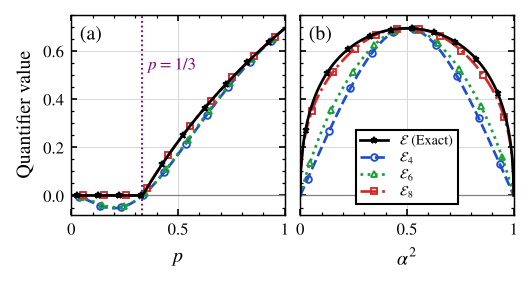

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(3.4, 1.75), sharey=True)
ax = axes[0]
for j, k in enumerate(KEYS):
    plot_q(ax, p_vals, werner[j], k, every=(10 + 4 * j, 40), ms=3.2)
ax.axhline(0, color="gray", lw=0.6, zorder=1)
ax.axvline(1/3, color="purple", lw=0.9, ls=(0, (1, 1.5)), zorder=1)
ax.text(0.36, 0.52, r"$p=1/3$", color="purple", fontsize=8, ha="left")
ax.set_xlabel(r"$p$"); ax.set_ylabel("Quantifier value")
ax.set_xlim(0, 1); ax.set_ylim(-0.08, 0.75)
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["0", "0.5", "1"])
panel_label(ax, "(a)")

ax = axes[1]
for j, k in enumerate(KEYS):
    plot_q(ax, x_vals, pure[j], k, every=(10 + 4 * j, 40), ms=3.2)
ax.axhline(0, color="gray", lw=0.6, zorder=1)
ax.set_xlabel(r"$\alpha^2$"); ax.set_xlim(0, 1)
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["0", "0.5", "1"])
panel_label(ax, "(b)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.02), fontsize=6.8,
          handlelength=2.0, borderpad=0.3, labelspacing=0.2)
fig.tight_layout(pad=0.2, w_pad=0.4)
save(fig, "fig_qubit_examples"); plt.show()

## 4. Many-body Hamiltonians, geometry and ground states (SM Sec. S6)

In [7]:
I2 = sp.identity(2, format="csr", dtype=complex)
SX = sp.csr_matrix(np.array([[0, 1], [1, 0]], dtype=complex))
SY = sp.csr_matrix(np.array([[0, -1j], [1j, 0]], dtype=complex))
SZ = sp.csr_matrix(np.array([[1, 0], [0, -1]], dtype=complex))

def site_ops(pairs, n):
    mats = [I2] * n
    for s, o in pairs:
        mats[s] = o
    out = mats[0]
    for m in mats[1:]:
        out = sp.kron(out, m, format="csr")
    return out

def H_TFIM(n, h):
    H = sum(-site_ops([(k, SX), (k + 1, SX)], n) for k in range(n - 1))
    return H + sum(-h * site_ops([(k, SZ)], n) for k in range(n))

def H_XXZ(n, delta):
    return sum(-site_ops([(k, SX), (k + 1, SX)], n) - site_ops([(k, SY), (k + 1, SY)], n)
               - delta * site_ops([(k, SZ), (k + 1, SZ)], n) for k in range(n - 1))

def H_LMG(n, h):
    H = sum(-site_ops([(i, SX), (j, SX)], n) / (n - 1)
            for i in range(n) for j in range(i + 1, n))
    return H + sum(-h * site_ops([(k, SZ)], n) for k in range(n))

def parity_penalty(n, c=10.0):      # c (1 - prod sz)/2 lifts the odd sector
    return c * (sp.identity(2**n, format="csr") - site_ops([(k, SZ) for k in range(n)], n)) / 2

def sz_penalty(n, c=1.0):           # c (sum sz)^2 lifts sectors with M != 0
    M = sum(site_ops([(k, SZ)], n) for k in range(n))
    return c * (M @ M)

def window(n, nA=5, nB=5):
    nC = n - nA - nB
    assert nC % 2 == 0
    A = list(range(nC // 2, nC // 2 + nA))
    B = list(range(nC // 2 + nA, nC // 2 + nA + nB))
    return A, B

def ground_state(H, penalty=None):
    Hp = H if penalty is None else H + penalty
    vals, vecs = eigsh(Hp, k=2, which="SA", tol=1e-13, ncv=40)
    i = np.argsort(vals)
    return vals[i], vecs[:, i[0]]

def pt_spectrum_pure(psi, n, A, B):
    keep = A + B
    rest = [s for s in range(n) if s not in keep]
    M = psi.reshape([2] * n).transpose(keep + rest).reshape(2**len(keep), -1)
    rho = M @ M.conj().T
    return pt_spectrum_rho(rho, len(A), len(B))

def pt_spectrum_rho(rho, nA, nB):
    dA, dB = 2**nA, 2**nB
    pt = rho.reshape(dA, dB, dA, dB).transpose(0, 3, 2, 1).reshape(dA * dB, dA * dB)
    return np.linalg.eigvalsh((pt + pt.conj().T) / 2)

N, (A12, B12) = 12, window(12)
print("n=12: A =", A12, " B =", B12, " C =", [s for s in range(12) if s not in A12 + B12])

PEN = {"TFIM": parity_penalty(N), "XXZ": sz_penalty(N), "LMG": parity_penalty(N)}
HAM = {"TFIM": H_TFIM, "XXZ": H_XXZ, "LMG": H_LMG}

GS_CHECK = {"max_residual": 0.0, "min_gap": np.inf}

def spectrum(model, x, n=N):
    H = HAM[model](n, x)
    vals, psi = ground_state(H, PEN[model] if n == N else None)
    e = np.real(np.vdot(psi, H @ psi))
    GS_CHECK["max_residual"] = max(GS_CHECK["max_residual"], np.linalg.norm(H @ psi - e * psi))
    GS_CHECK["min_gap"] = min(GS_CHECK["min_gap"], vals[1] - vals[0])
    lam = pt_spectrum_pure(psi, n, *window(n))
    # sanity: normalization of rho^Gamma and p2 = purity
    assert abs(lam.sum() - 1) < 1e-10
    return lam, vals[1] - vals[0]

n=12: A = [1, 2, 3, 4, 5]  B = [6, 7, 8, 9, 10]  C = [0, 11]


### Ground-state scans (main text Fig. 2)

Grids include every point quoted in the text ($h=0.85$, $h=2$,
$\Delta=-0.5$, $\Delta=-2.5$, $\Delta=-4$).

In [8]:
grids = {"TFIM": np.round(np.arange(0, 2.0001, 0.05), 4),
         "XXZ":  np.unique(np.round(np.r_[np.arange(-4, 1.0001, 0.125), 0.95, 0.975, 0.99], 4)),
         "LMG":  np.round(np.arange(0, 3.0001, 0.075), 4)}

scans = {}
t0 = time.time()
for model, grid in grids.items():
    out = np.array([all_quantifiers(spectrum(model, x)[0]) for x in grid]).T
    scans[model] = out
    viol = np.sum((out[1] > out[2] + 1e-10) | (out[2] > out[3] + 1e-10) | (out[3] > out[0] + 1e-10))
    print(f"{model}: {len(grid)} points, ordering violations = {viol}")
print(f"scan time {time.time() - t0:.0f} s")
print(f"ground states: max residual |H psi - E psi| = {GS_CHECK['max_residual']:.1e}, "
      f"smallest gap inside the symmetry sector = {GS_CHECK['min_gap']:.3f}")

res = minimize_scalar(lambda h: -all_quantifiers(spectrum("LMG", h)[0])[0],
                      bounds=(0.3, 1.2), method="bounded", options={"xatol": 1e-4})
h_lmg_peak = float(res.x)
print(f"LMG: maximum of E at h = {h_lmg_peak:.3f}")

np.savez(f"{FIGDIR}/manybody_scans.npz", **{f"{m}_grid": grids[m] for m in grids},
         **{f"{m}_{k}": scans[m][j] for m in scans for j, k in enumerate(KEYS)})

def at(model, x):
    j = np.argmin(abs(grids[model] - x)); assert abs(grids[model][j] - x) < 1e-9
    return dict(zip(KEYS, np.round(scans[model][:, j], 3)))

quoted = {"TFIM h=0.85": at("TFIM", 0.85), "TFIM h=2": at("TFIM", 2.0),
          "XXZ D=-0.5": at("XXZ", -0.5), "XXZ D=-2.5": at("XXZ", -2.5),
          "XXZ D=-4": at("XXZ", -4.0), "TFIM h=0": at("TFIM", 0.0)}
for k, v in quoted.items():
    print(k, v)

# zero crossings of E4, E6 on the antiferromagnetic side of the XXZ chain
for j, k in ((1, "E4"), (2, "E6")):
    y, g = scans["XXZ"][j], grids["XXZ"]
    idx = np.where((y[:-1] < 0) & (y[1:] >= 0))[0]
    print(f"XXZ: {k} becomes positive at Delta ~ {g[idx[0]]:.3f}..{g[idx[0] + 1]:.3f}")
gap_frac = (scans["TFIM"][3] - scans["TFIM"][1]) / (scans["TFIM"][0] - scans["TFIM"][1])
sel = (grids["TFIM"] >= 0.7) & (grids["TFIM"] <= 1.0)
print(f"TFIM: fraction of the E4 gap recovered by E8 for 0.7<=h<=1: "
      f"{gap_frac[sel].min():.2f} to {gap_frac[sel].max():.2f}")

TFIM: 41 points, ordering violations = 0


XXZ: 44 points, ordering violations = 0


LMG: 41 points, ordering violations = 0
scan time 62 s
ground states: max residual |H psi - E psi| = 1.5e-12, smallest gap inside the symmetry sector = 0.076


LMG: maximum of E at h = 0.712
TFIM h=0.85 {'E': np.float64(0.542), 'E4': np.float64(0.245), 'E6': np.float64(0.29), 'E8': np.float64(0.38)}
TFIM h=2 {'E': np.float64(0.238), 'E4': np.float64(0.004), 'E6': np.float64(0.025), 'E8': np.float64(0.195)}
XXZ D=-0.5 {'E': np.float64(0.803), 'E4': np.float64(0.195), 'E6': np.float64(0.217), 'E8': np.float64(0.433)}
XXZ D=-2.5 {'E': np.float64(0.696), 'E4': np.float64(0.002), 'E6': np.float64(0.038), 'E8': np.float64(0.413)}
XXZ D=-4 {'E': np.float64(0.452), 'E4': np.float64(-0.061), 'E6': np.float64(-0.049), 'E8': np.float64(0.317)}
TFIM h=0 {'E': np.float64(0.0), 'E4': np.float64(0.0), 'E6': np.float64(0.0), 'E8': np.float64(0.0)}
XXZ: E4 becomes positive at Delta ~ -2.625..-2.500
XXZ: E6 becomes positive at Delta ~ -2.875..-2.750
TFIM: fraction of the E4 gap recovered by E8 for 0.7<=h<=1: 0.42 to 0.59


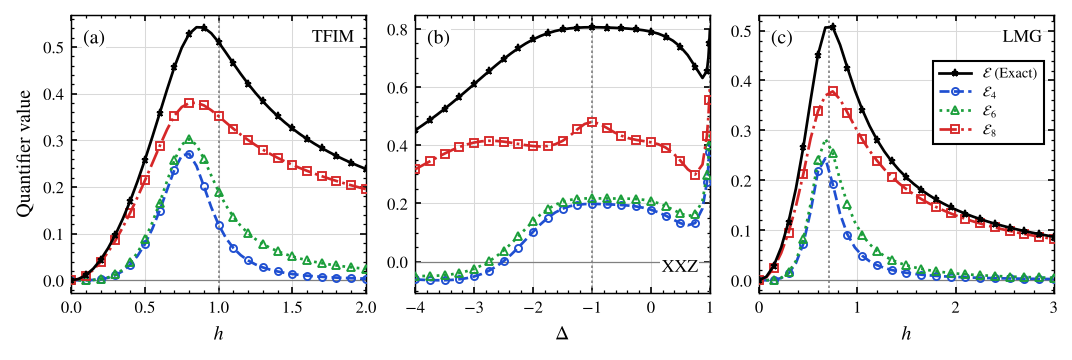

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.25))
setup = [("TFIM", r"$h$", [1.0], "(a)", 2),
         ("XXZ", r"$\Delta$", [-1.0, 1.0], "(b)", 2),
         ("LMG", r"$h$", [h_lmg_peak], "(c)", 2)]
for ax, (m, xl, vl, tag, ev) in zip(axes, setup):
    for j, k in enumerate(KEYS):
        plot_q(ax, grids[m], scans[m][j], k, every=ev, ms=3.4)
    ax.axhline(0, color="gray", lw=0.6, zorder=1)
    for v in vl:
        ax.axvline(v, color="gray", lw=0.8, ls=(0, (1.5, 1.5)), zorder=1)
    ax.set_xlabel(xl); ax.set_xlim(grids[m].min(), grids[m].max())
    panel_label(ax, tag)
    ytxt, va = (0.06, "bottom") if m == "XXZ" else (0.95, "top")
    ax.text(0.96, ytxt, m, transform=ax.transAxes, ha="right", va=va, fontsize=8.5,
            bbox=dict(fc="white", ec="none", pad=0.6))
axes[0].set_ylabel("Quantifier value")
axes[2].legend(loc="upper right", bbox_to_anchor=(0.99, 0.86), fontsize=7)
fig.tight_layout(pad=0.2, w_pad=0.6)
save(fig, "fig_manybody_examples"); plt.show()

## 5. Thermal state (main text Fig. 3)

TFIM, $h=0.9$, $n=10$, $A=\{1,\dots,4\}$, $B=\{5,\dots,8\}$, $C=\{0,9\}$.
The Hamiltonian is diagonalized once. The temperature at which the PT loses
its last negative eigenvalue (sudden death) and the zero crossings of
$\mathcal E_4,\mathcal E_6,\mathcal E_8$ are located by bisection.

In [10]:
n_th, h_th = 10, 0.9
A_th, B_th = window(n_th, 4, 4)
evals_th, evecs_th = np.linalg.eigh(H_TFIM(n_th, h_th).toarray())
evals_th = evals_th - evals_th[0]

def thermal_pt_spectrum(T):
    w = np.exp(-evals_th / T); w /= w.sum()
    rho = (evecs_th * w) @ evecs_th.conj().T
    keep = A_th + B_th; rest = [s for s in range(n_th) if s not in keep]
    d = 2**len(keep)
    perm = keep + rest
    r = rho.reshape([2] * (2 * n_th)).transpose(perm + [n_th + s for s in perm])
    r = r.reshape(d, 2**len(rest), d, 2**len(rest))
    rho_AB = np.einsum("aibi->ab", r)
    return pt_spectrum_rho(rho_AB, len(A_th), len(B_th))

T_vals = np.geomspace(1e-3, 1.5, 61)
thermal = np.array([all_quantifiers(thermal_pt_spectrum(T)) for T in T_vals]).T

T_sd = brentq(lambda T: thermal_pt_spectrum(T).min(), 0.5, 3.0, xtol=1e-6)
T_cross = {}
for j, k in ((1, "E4"), (2, "E6"), (3, "E8")):
    f = lambda T, j=j: all_quantifiers(thermal_pt_spectrum(T))[j]
    T_cross[k] = brentq(f, 0.05, T_sd, xtol=1e-6)
print(f"sudden death at T = {T_sd:.3f};  zero crossings:",
      {k: round(v, 3) for k, v in T_cross.items()})
print("T -> 0 values:", dict(zip(KEYS, np.round(thermal[:, 0], 3))))
json.dump({"T_sudden_death": T_sd, "T_cross": T_cross},
          open(f"{FIGDIR}/thermal_thresholds.json", "w"), indent=1)

sudden death at T = 1.209;  zero crossings: {'E4': 0.163, 'E6': 0.203, 'E8': 0.26}
T -> 0 values: {'E': np.float64(0.498), 'E4': np.float64(0.165), 'E6': np.float64(0.228), 'E8': np.float64(0.35)}


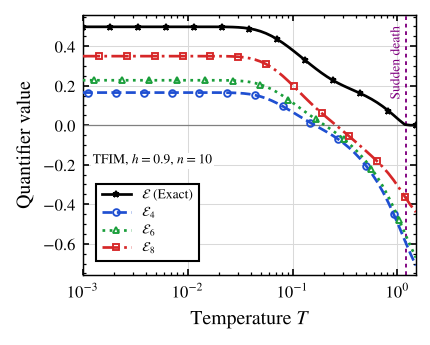

In [11]:
fig, ax = plt.subplots(figsize=(2.72, 2.15))      # printed at 0.8 of the column width
for j, k in enumerate(KEYS):
    plot_q(ax, T_vals, thermal[j], k, every=(j, 5), ms=3.2)
ax.axhline(0, color="gray", lw=0.6, zorder=1)
ax.axvline(T_sd, color="purple", lw=0.9, ls=(0, (2, 2)), zorder=2)
ax.text(T_sd * 0.93, 0.13, "Sudden death", color="purple", rotation=90,
        ha="right", va="bottom", fontsize=6.5)
ax.set_xscale("log"); ax.set_xlim(T_vals[0], T_vals[-1]); ax.set_ylim(-0.76, 0.56)
ax.set_xlabel(r"Temperature $T$"); ax.set_ylabel("Quantifier value")
ax.legend(loc="lower left", bbox_to_anchor=(0.02, 0.03), fontsize=6.5)
ax.text(0.03, 0.44, rf"TFIM, $h={h_th}$, $n={n_th}$", transform=ax.transAxes,
        ha="left", va="center", fontsize=6.5, bbox=dict(fc="white", ec="none", pad=0.6))
fig.tight_layout(pad=0.2)
save(fig, "fig_thermal"); plt.show()

## 6. High orders on two-qubit states (End Matter Fig. 4)

In [12]:
K_q = list(range(4, 17, 2))
E_w, K_w, EK_w, _ = K_sweep(werner_spec(0.5), K_q, hankel_upto=16)
E_p, K_p, EK_p, _ = K_sweep(pure_spec(0.25), K_q, hankel_upto=16)       # alpha = 1/2
for name, E, Ks, EKs in (("Werner p=1/2", E_w, K_w, EK_w), ("pure alpha=1/2", E_p, K_p, EK_p)):
    print(name, "E =", round(E, 4), dict(zip(Ks, np.round(EKs, 4))))
print("s(Werner) =", distinct_magnitudes(werner_spec(0.5)),
      " s(pure) =", distinct_magnitudes(pure_spec(0.25)))

Werner p=1/2 E = 0.2231 {4: np.float64(0.1703), 6: np.float64(0.1743), 8: np.float64(0.2231), 10: np.float64(0.2231), 12: np.float64(0.2231), 14: np.float64(0.2231), 16: np.float64(0.2231)}
pure alpha=1/2 E = 0.6238 {4: np.float64(0.47), 6: np.float64(0.5176), 8: np.float64(0.6041), 10: np.float64(0.6061), 12: np.float64(0.6238), 14: np.float64(0.6238), 16: np.float64(0.6238)}
s(Werner) = 2  s(pure) = 3


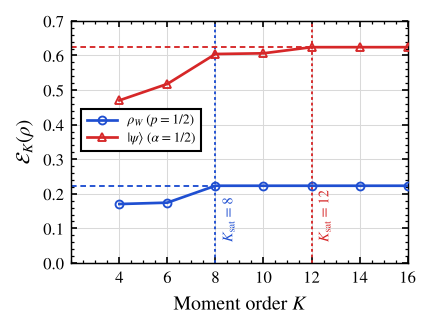

In [13]:
fig, ax = plt.subplots(figsize=(2.72, 2.05))      # printed at 0.8 of the column width
for E, Ks, EKs, c, mk, lab in ((E_w, K_w, EK_w, COL["E4"], "o", r"$\rho_W$ ($p=1/2$)"),
                              (E_p, K_p, EK_p, COL["E8"], "^", r"$|\psi\rangle$ ($\alpha=1/2$)")):
    ax.axhline(E, color=c, lw=0.9, ls=(0, (3, 2)), zorder=1)
    ax.plot(Ks, EKs, color=c, marker=mk, ms=3.8, markerfacecolor="none", label=lab, zorder=4)
    Ksat = next(K for K, v in zip(Ks, EKs) if abs(v - E) < 1e-10)
    ax.axvline(Ksat, color=c, lw=0.9, ls=(0, (1.5, 1.5)), zorder=1)
    ax.text(Ksat + 0.25, 0.06, rf"$K_{{\rm sat}}={Ksat}$", color=c, rotation=90,
            fontsize=7, ha="left", va="bottom")
ax.set_xlim(2, 16); ax.set_ylim(0, 0.7); ax.set_xticks(range(4, 17, 2))
ax.set_xlabel(r"Moment order $K$"); ax.set_ylabel(r"$\mathcal{E}_K(\rho)$")
ax.legend(loc="center left", bbox_to_anchor=(0.01, 0.55), fontsize=6.5)
fig.tight_layout(pad=0.2)
save(fig, "fig_K_convergence_combined"); plt.show()

## 7. High orders on many-body states (End Matter Fig. 5)

Same geometry and symmetry sectors as Fig. 2. Eigenvalues below $10^{-12}$
in modulus are numerical zeros and are dropped. The number $s$ of distinct
nonzero magnitudes is counted with relative tolerance $10^{-9}$ (and
$10^{-6}$ as a robustness check). Values come from `SpectrumRules`; the
moment-only Hankel route is evaluated alongside up to $K=80$ and must agree.

In [14]:
K_mb = [4, 6, 8, 10, 12] + list(range(16, 161, 4))
mb_points = {"TFIM": 0.85, "XXZ": -0.5, "LMG": round(h_lmg_peak, 2)}
mb_conv = {}
for m, x in mb_points.items():
    lam, gap = spectrum(m, x)
    lam = lam[np.abs(lam) > 1e-12]
    s9, s6 = distinct_magnitudes(lam, 1e-9), distinct_magnitudes(lam, 1e-6)
    t0 = time.time()
    E, Ks, EKs, info = K_sweep(lam, K_mb, hankel_upto=80)
    gaps = [E - v for v in EKs]
    K_exact = next((K for K, g in zip(Ks, gaps) if abs(g) < 1e-14), None)
    mb_conv[m] = dict(x=x, E=E, K=Ks, EK=EKs, s=s9, s_loose=s6, Ksat=4 * s9,
                      K_exact=K_exact, lanczos_points=info["n_points"],
                      K_hankel=info["K_hankel"], hankel_dev=info["max_dev"])
    print(f"{m} ({x}): E={E:.4f}, s={s9} (tol 1e-6: {s6}), K_sat=4s={4*s9}, "
          f"first exact order={K_exact} ({time.time()-t0:.0f}s)")
    print(f"   E_4,6,8 = {np.round(EKs[:3], 3)};  gaps: " +
          ", ".join(f"K={K}: {g:.1e}" for K, g in zip(Ks, gaps) if K in (60, 68, 80, 120, 140, 160)))
    print(f"   Hankel route valid up to K={info['K_hankel']}, max deviation {info['max_dev']:.1e}")
    if K_exact is not None:
        assert K_exact == 4 * s9 and info["n_points"] == s9      # Theorem 2
json.dump(mb_conv, open(f"{FIGDIR}/manybody_K_convergence.json", "w"), indent=1)

TFIM (0.85): E=0.5420, s=407 (tol 1e-6: 407), K_sat=4s=1628, first exact order=None (24s)
   E_4,6,8 = [0.245 0.29  0.38 ];  gaps: K=60: 4.1e-03, K=68: 3.3e-03, K=80: 2.3e-03, K=120: 2.3e-04, K=140: 1.6e-04, K=160: 9.6e-05
   Hankel route valid up to K=68, max deviation 8.5e-11


XXZ (-0.5): E=0.8027, s=638 (tol 1e-6: 638), K_sat=4s=2552, first exact order=None (27s)
   E_4,6,8 = [0.195 0.217 0.433];  gaps: K=60: 2.7e-02, K=68: 2.3e-02, K=80: 2.0e-02, K=120: 1.2e-02, K=140: 9.7e-03, K=160: 8.2e-03
   Hankel route valid up to K=80, max deviation 0.0e+00


LMG (0.71): E=0.5126, s=36 (tol 1e-6: 36), K_sat=4s=144, first exact order=144 (11s)
   E_4,6,8 = [0.226 0.277 0.378];  gaps: K=60: 1.1e-04, K=68: 5.3e-05, K=80: 2.3e-05, K=120: 5.1e-08, K=140: 7.2e-11, K=160: 0.0e+00
   Hankel route valid up to K=60, max deviation 6.7e-10


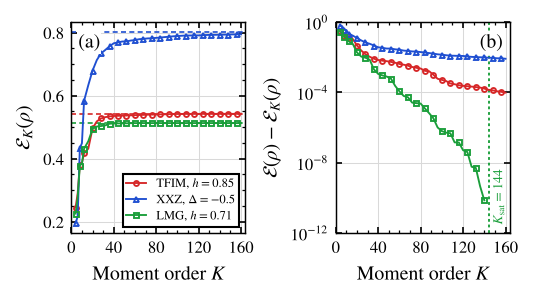

In [15]:
MB_STY = {"TFIM": (COL["E8"], "o", r"TFIM, $h=0.85$"),
          "XXZ": (COL["E4"], "^", r"XXZ, $\Delta=-0.5$"),
          "LMG": (COL["E6"], "s", rf"LMG, $h={mb_points['LMG']}$")}
fig, (ax, axg) = plt.subplots(1, 2, figsize=(3.4, 1.85))
for m, d in mb_conv.items():
    c, mk, lab = MB_STY[m]
    K, EK = np.array(d["K"]), np.array(d["EK"])
    gap = d["E"] - EK
    ax.axhline(d["E"], color=c, lw=0.8, ls=(0, (3, 2)), zorder=1)
    ax.plot(K, EK, color=c, marker=mk, ms=2.4, markerfacecolor="none", lw=0.9,
            markevery=2, label=lab, zorder=4)
    keep = gap > 1e-14
    axg.plot(K[keep], gap[keep], color=c, marker=mk, ms=2.4, markerfacecolor="none",
             lw=0.9, markevery=2, zorder=4)
    if d["K_exact"] is not None:
        axg.axvline(d["K_exact"], color=c, lw=0.9, ls=(0, (1.5, 1.5)), zorder=2)
        axg.text(d["K_exact"] + 4, 3e-12, rf"$K_{{\rm sat}}={d['K_exact']}$", color=c,
                 rotation=90, ha="left", va="bottom", fontsize=6.5)
for a in (ax, axg):
    a.set_xlim(0, 164); a.set_xticks([0, 40, 80, 120, 160]); a.set_xlabel(r"Moment order $K$")
ax.set_ylabel(r"$\mathcal{E}_K(\rho)$")
axg.set_yscale("log"); axg.set_ylim(1e-12, 1); axg.set_yticks([1e-12, 1e-8, 1e-4, 1]); axg.set_ylabel(r"$\mathcal{E}(\rho)-\mathcal{E}_K(\rho)$")
ax.legend(loc="lower right", fontsize=6.0, handlelength=1.6, borderpad=0.3)
panel_label(ax, "(a)"); panel_label(axg, "(b)", x=0.96, ha="right")
fig.tight_layout(pad=0.2, w_pad=0.5)
save(fig, "fig_manybody_K_convergence"); plt.show()

## 8. Finite statistics (End Matter Appendix C, Fig. 7)

Each of $p_2,p_4,p_6$ receives independent Gaussian noise of relative width
$1/\sqrt{N_s}$ (a generic scaling, not the variance of a specific protocol).
Estimator: $\mathcal E_6$ when the noisy reduced moments are admissible,
$0<\mu_2<1$ and $\mu_2^2<\mu_3<\mu_2$ (SM Lemma S2), otherwise $\mathcal E_4$.
8000 trials for every $N_s$.

In [16]:
rng = np.random.default_rng(SEED)
N_list = [1e2, 3e2, 1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6]
n_trials = 8000

def admissible(mu2, mu3):
    return (mu2 > 0) & (mu2 < 1) & (mu3 > mu2**2) & (mu3 < mu2)

def estimator(p2, p4, p6):
    mu2, mu3 = p4 / p2**2, p6 / p2**3
    ok = admissible(mu2, mu3)
    out = 1.5 * np.log(p2) - 0.5 * np.log(p4)                 # E4
    a = np.where(ok, (mu2 - mu3) / (1 - mu2), 1.0)
    wa = np.where(ok, (1 - mu2)**2 / (1 - 2 * mu2 + mu3), 1.0)
    E6 = 0.5 * np.log(p2) + np.log(wa / np.sqrt(a) + 1 - wa)
    return np.where(ok, E6, out), ok

noise = {}
lam_tfim = spectrum("TFIM", 0.85)[0]
for name, lam in (("Werner", werner_spec(0.5)), ("TFIM", lam_tfim)):
    m = moments(lam, 3); E = exact_E(lam)
    E6 = E6_q(m[2], m[4], m[6])
    rec = {"E": E, "E6": E6, "gap": E - E6, "N": N_list, "inadmissible": [], "rmse": []}
    for Ns in N_list:
        p = {k: m[k] * (1 + rng.normal(size=n_trials) / np.sqrt(Ns)) for k in (2, 4, 6)}
        assert np.all(p[2] > 0) and np.all(p[4] > 0)
        est, ok = estimator(p[2], p[4], p[6])
        rec["inadmissible"].append(float(1 - ok.mean()))
        rec["rmse"].append(float(np.sqrt(np.mean((est - E)**2))))
    noise[name] = rec
    print(f"{name}: E={E:.3f}, E6={E6:.3f}, gap={E-E6:.3f}")
    for Ns, f, r in zip(N_list, rec["inadmissible"], rec["rmse"]):
        print(f"   N_s={Ns:8.0e}  inadmissible={100*f:5.1f}%  rmse={r:.3f}")
json.dump(noise, open(f"{FIGDIR}/noise_results.json", "w"), indent=1)

Werner: E=0.223, E6=0.174, gap=0.049
   N_s=   1e+02  inadmissible= 47.2%  rmse=0.179
   N_s=   3e+02  inadmissible= 42.7%  rmse=0.110
   N_s=   1e+03  inadmissible= 36.2%  rmse=0.073
   N_s=   3e+03  inadmissible= 26.4%  rmse=0.058
   N_s=   1e+04  inadmissible= 12.2%  rmse=0.052
   N_s=   3e+04  inadmissible=  2.3%  rmse=0.050
   N_s=   1e+05  inadmissible=  0.0%  rmse=0.049
   N_s=   3e+05  inadmissible=  0.0%  rmse=0.049
   N_s=   1e+06  inadmissible=  0.0%  rmse=0.049
TFIM: E=0.542, E6=0.290, gap=0.252
   N_s=   1e+02  inadmissible= 19.7%  rmse=0.311
   N_s=   3e+02  inadmissible=  6.7%  rmse=0.275
   N_s=   1e+03  inadmissible=  0.2%  rmse=0.260
   N_s=   3e+03  inadmissible=  0.0%  rmse=0.254
   N_s=   1e+04  inadmissible=  0.0%  rmse=0.253
   N_s=   3e+04  inadmissible=  0.0%  rmse=0.253
   N_s=   1e+05  inadmissible=  0.0%  rmse=0.252
   N_s=   3e+05  inadmissible=  0.0%  rmse=0.252
   N_s=   1e+06  inadmissible=  0.0%  rmse=0.252


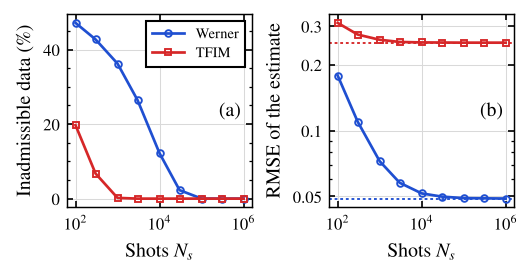

In [17]:
NCOL = {"Werner": COL["E4"], "TFIM": COL["E8"]}
NMK = {"Werner": "o", "TFIM": "s"}
fig, axes = plt.subplots(1, 2, figsize=(3.4, 1.7))
for name, rec in noise.items():
    c = NCOL[name]
    axes[0].plot(rec["N"], 100 * np.array(rec["inadmissible"]), color=c, marker=NMK[name],
                 ms=3.2, markerfacecolor="none", label=name)
    axes[1].plot(rec["N"], rec["rmse"], color=c, marker=NMK[name], ms=3.2, markerfacecolor="none")
    axes[1].axhline(rec["gap"], color=c, lw=0.9, ls=(0, (1.5, 1.5)), zorder=1)
for a in axes:
    a.set_xscale("log"); a.set_xlabel(r"Shots $N_s$")
axes[0].set_ylabel(r"Inadmissible data (\%)" if plt.rcParams["text.usetex"] else "Inadmissible data (%)")
axes[1].set_yscale("log"); axes[1].set_ylabel("RMSE of the estimate")
axes[1].set_yticks([0.05, 0.1, 0.2, 0.3]); axes[1].set_yticklabels(["0.05", "0.1", "0.2", "0.3"])
axes[1].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axes[0].legend(loc="upper right", fontsize=7)
panel_label(axes[0], "(a)", x=0.94, y=0.55, ha="right"); panel_label(axes[1], "(b)", x=0.94, y=0.55, ha="right")
fig.tight_layout(pad=0.2, w_pad=0.5)
save(fig, "fig_noise_robustness"); plt.show()

## 9. Beyond exact diagonalization: DMRG (End Matter Appendix D, Fig. 6)

Ground states by two-site DMRG in `quimb`. The quimb Hamiltonians are written
with spin operators $S^a=\sigma^a/2$; the couplings below reproduce the
Hamiltonians of the main text exactly, which is checked by comparing the full
spectra for $n=8$, and the whole pipeline is checked against ED at $n=12$.
Each $n$ is run with two bond-dimension schedules; a point is kept only if the
energies agree to $10^{-6}$, the values of $\mu_2$ to $10^{-5}$, the
moments satisfy the admissibility conditions, and (TFIM) the DMRG state has
definite $\mathbb Z_2$ parity, i.e. it is the true ground state and not a
symmetry-broken mixture of the two lowest states.

In [18]:
try:
    import quimb as qu
    import quimb.tensor as qtn
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "quimb"])
    import quimb as qu
    import quimb.tensor as qtn

MPO = {"TFIM": lambda n, h: qtn.MPO_ham_ising(n, j=4.0, bx=2 * h, S=0.5),
       "XXZ":  lambda n, d: qtn.MPO_ham_heis(n, j=(-4.0, -4.0, -4.0 * d), bz=0.0, S=0.5)}
for m, x in (("TFIM", 0.85), ("XXZ", 0.5)):
    e_mpo = np.linalg.eigvalsh(MPO[m](8, x).to_dense())
    e_ed = np.linalg.eigvalsh(HAM[m](8, x).toarray())
    print(f"{m}: max |spectrum(MPO) - spectrum(ED)| at n=8 = {np.max(abs(e_mpo - e_ed)):.1e}")

SCHED = {"A": ([20, 40, 80, 120, 160, 200], 1e-10),
         "B": ([20, 40, 80, 120, 160, 200, 280, 350], 1e-11)}

def dmrg_point(m, x, n, sched):
    bds, tol = SCHED[sched]
    d = qtn.DMRG2(MPO[m](n, x), bond_dims=bds, cutoffs=tol)
    d.solve(tol=tol, max_sweeps=40, verbosity=0)
    A, B = window(n)
    psi = d.state
    par = None
    if m == "TFIM":   # quimb field is along x, so the Z2 parity is prod_k sigma^x_k
        X = qu.pauli("X")
        phi = psi.copy()
        for i in range(n):
            phi.gate_(X, i, contract=True)
        par = float(np.real(psi.H @ phi))
    rho = d.state.partial_trace_to_mpo(A + B).to_dense()
    rho = (rho + rho.conj().T) / 2
    lam = pt_spectrum_rho(rho, len(A), len(B))
    return float(np.real(d.energy)), lam, par

def dmrg_scan(m, x, n_list):
    recs = []
    for n in n_list:
        t0 = time.time()
        eA, lamA, _ = dmrg_point(m, x, n, "A")
        eB, lamB, parB = dmrg_point(m, x, n, "B")
        mA, mB = moments(lamA), moments(lamB)
        mu2A, mu2B = mA[4] / mA[2]**2, mB[4] / mB[2]**2
        mu3B = mB[6] / mB[2]**3
        ok = abs(eA - eB) < 1e-6 and abs(mu2A - mu2B) < 1e-5 and bool(admissible(mu2B, mu3B))
        q = all_quantifiers(lamB)
        if parB is not None:
            ok = ok and abs(abs(parB) - 1) < 1e-6
        recs.append(dict(n=n, converged=ok, dE=abs(eA - eB), dmu2=abs(mu2A - mu2B), parity=parB,
                         **dict(zip(KEYS, q))))
        print(f"{m} n={n}: ok={ok} dE={abs(eA-eB):.1e} dmu2={abs(mu2A-mu2B):.1e} "
              + (f"parity={parB:+.6f} " if parB is not None else "")
              + f"E,E4,E6,E8={np.round(q, 3)} ({time.time()-t0:.0f}s)")
    return recs

# Set REUSE_DMRG=1 in the environment to reuse figures/dmrg_results.json.
if os.environ.get("REUSE_DMRG") and os.path.exists(f"{FIGDIR}/dmrg_results.json"):
    dmrg = json.load(open(f"{FIGDIR}/dmrg_results.json"))
else:
    dmrg = {"TFIM": dmrg_scan("TFIM", 0.85, [12, 16, 20, 24, 28, 32, 36]),
            "XXZ":  dmrg_scan("XXZ", 0.5, [12, 16, 20, 24, 28, 32, 36])}
ed_ref = {"TFIM": all_quantifiers(spectrum("TFIM", 0.85)[0]),
          "XXZ": all_quantifiers(spectrum("XXZ", 0.5)[0])}
for m in dmrg:
    r12 = dmrg[m][0]
    print(f"{m}: |DMRG - ED| at n=12 = {max(abs(r12[k] - e) for k, e in zip(KEYS, ed_ref[m])):.1e}")
json.dump(dmrg, open(f"{FIGDIR}/dmrg_results.json", "w"), indent=1)

TFIM: max |spectrum(MPO) - spectrum(ED)| at n=8 = 9.1e-14
XXZ: max |spectrum(MPO) - spectrum(ED)| at n=8 = 3.1e-14


TFIM n=12: ok=True dE=1.6e-09 dmu2=1.1e-06 parity=+1.000000 E,E4,E6,E8=[0.542 0.245 0.29  0.38 ] (7s)


TFIM n=16: ok=True dE=3.0e-09 dmu2=8.5e-08 parity=+1.000000 E,E4,E6,E8=[0.38  0.095 0.117 0.192] (1s)


TFIM n=20: ok=True dE=4.6e-09 dmu2=1.8e-07 parity=+1.000000 E,E4,E6,E8=[0.283 0.03  0.041 0.097] (1s)


TFIM n=24: ok=True dE=4.9e-09 dmu2=1.9e-07 parity=+1.000000 E,E4,E6,E8=[0.226 0.008 0.014 0.053] (3s)


TFIM n=28: ok=True dE=5.7e-09 dmu2=1.8e-07 parity=+1.000000 E,E4,E6,E8=[0.193 0.002 0.006 0.036] (5s)


... (6 outputs left out)

XXZ n=28: ok=True dE=1.2e-08 dmu2=2.0e-07 E,E4,E6,E8=[0.584 0.059 0.088 0.204] (9s)


XXZ n=32: ok=True dE=1.5e-08 dmu2=2.3e-07 E,E4,E6,E8=[0.576 0.058 0.087 0.201] (16s)


XXZ n=36: ok=True dE=1.8e-08 dmu2=1.7e-07 E,E4,E6,E8=[0.571 0.058 0.087 0.199] (26s)


TFIM: |DMRG - ED| at n=12 = 1.4e-06
XXZ: |DMRG - ED| at n=12 = 5.1e-07


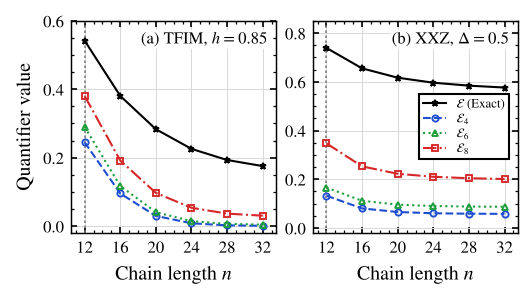

In [19]:
N_SHOW = 32   # largest n converged for both models
fig, axes = plt.subplots(1, 2, figsize=(3.4, 1.85))
for ax, (m, lab, tag) in zip(axes, (("TFIM", r"TFIM, $h=0.85$", "(a)"),
                                     ("XXZ", r"XXZ, $\Delta=0.5$", "(b)"))):
    recs = [r for r in dmrg[m] if r["converged"] and r["n"] <= N_SHOW]   # same range in both panels
    n = [r["n"] for r in recs]
    for k in KEYS:
        plot_q(ax, n, [r[k] for r in recs], k, ms=3.0, lw=1.0)
    ax.axvline(12, color="gray", lw=0.8, ls=(0, (1.5, 1.5)), zorder=1)
    ax.set_xlabel(r"Chain length $n$"); ax.set_xlim(10.5, 33.5); ax.set_xticks([12, 16, 20, 24, 28, 32])
    ax.text(0.96, 0.95, tag + " " + lab, transform=ax.transAxes, ha="right", va="top",
            fontsize=8, bbox=dict(fc="white", ec="none", pad=0.6))
axes[0].set_ylabel("Quantifier value")
axes[0].set_ylim(-0.02, 0.6); axes[1].set_ylim(-0.02, 0.85)
axes[1].legend(loc="center right", bbox_to_anchor=(0.99, 0.5), fontsize=6.2,
               handlelength=1.8, borderpad=0.3, labelspacing=0.15)
fig.tight_layout(pad=0.2, w_pad=0.5)
save(fig, "fig_dmrg_scaling"); plt.show()

## 10. Odd moments and normalization: the bound from all moments (SM Sec. S8, Fig. S1)

Theorem 1 uses only $p_2,p_4,\dots,p_K$. To see what is lost, we compute
numerically the smallest $\sum_i|x_i|$ over all measures
$\tau=\sum_i x_i^2\delta_{x_i}$ on $0<|x|\le\sqrt{p_2}$ that reproduce
$p_1=1$ and every moment $p_2,p_3,\dots,p_K$ (written $\mathcal E_K^{\rm all}$
after taking the logarithm). This is a linear program over the weights on a
grid, refined around the support of the solution. A grid value can only lie
above the infimum, so every reported value is certified by the dual solution
of the program, verified on the whole interval in exact rational arithmetic
(see `E_all` and `rigorous_max`). Certified and
grid values differ by less than $2\times10^{-4}$. With the odd moments and $p_1$
removed, the same program reproduces $\mathcal E_K$, which validates it. We also record where the $p_3$-PPT test
$p_3<p_2^2$ of Elben et al. detects entanglement.

In [20]:
from scipy.optimize import linprog

def _lp(lam, K, full, eps, npts, rounds):
    lam = np.asarray(lam, float)
    p = {k: float(np.sum(lam**k)) for k in range(1, K + 1)}
    R = np.sqrt(p[2])
    ks = ([1] if full else []) + [k for k in range(2, K + 1) if full or k % 2 == 0]
    b = np.array([p[k] for k in ks])
    g = R * np.geomspace(1e-8, 1, npts)
    x = np.concatenate([-g[::-1], g]) if full else g
    # extra grid points can only lower the grid value towards the infimum
    mags = np.unique(np.abs(lam[np.abs(lam) > 1e-12]))
    x = np.unique(np.concatenate([x, mags] + ([-mags] if full else [])))
    for it in range(rounds + 1):
        A = np.array([(1 / x if k == 1 else x**(k - 2)) for k in ks]) / np.abs(b)[:, None]
        m, nv = A.shape
        res = linprog(np.concatenate([1 / np.abs(x), np.zeros(2 * m)]),
                      A_eq=np.hstack([A, np.eye(m), -np.eye(m)]), b_eq=b / np.abs(b),
                      bounds=[(0, None)] * nv + [(0, eps)] * (2 * m), method="highs")
        if res.status != 0:
            return np.nan
        t = res.x[:nv]
        sup = x[t > 1e-14 * t.max()]
        if it == rounds:
            break
        x = np.unique(np.concatenate([x] + [s * np.linspace(0.97, 1.03, 301) for s in sup]))
        x = x[(np.abs(x) <= R) & (x != 0)]
        if not full:
            x = x[x > 0]
    return float(np.log(res.fun))

from fractions import Fraction
import sympy as sy

def rigorous_max(coeffs, R):
    # Upper bound on max of P(u) = sum_j coeffs[j] u^j over 0 <= u <= R, all exact
    # rationals. The real roots of P' are isolated exactly (sympy, intervals of
    # width 1e-30); inside an isolating interval [a, b] the maximum is at most
    # P(a) + (b - a) L, with L >= max |P'| on [0, R]. Endpoints are evaluated exactly.
    u = sy.Symbol("u")
    P = sy.Poly(sum(sy.Rational(c.numerator, c.denominator) * u**j for j, c in enumerate(coeffs)), u, domain="QQ")
    dP = P.diff(u)
    Rr = sy.Rational(R.numerator, R.denominator)
    cand = [P.eval(0), P.eval(Rr)]
    if dP.degree() >= 1:
        L = sum(abs(c) * Rr**k for k, c in enumerate(reversed(dP.all_coeffs())))
        for (a, b_), _ in dP.intervals(eps=sy.Rational(1, 10**30)):
            a, b_ = sy.Rational(a), sy.Rational(b_)
            if b_ < 0 or a > Rr:
                continue
            a, b_ = max(a, sy.Integer(0)), min(b_, Rr)
            cand.append(P.eval(a) + (b_ - a) * L)
    m = max(cand)
    return Fraction(int(m.p), int(m.q))

CERT = {"max_grid_minus_cert": 0.0}

def E_all(lam, K, npts=3000, rounds=3):
    # Bound from p1, p2, ..., pK with a dual certificate.
    # The grid LP gives a value at or above the infimum. Its dual solution y
    # defines g(x) = y1/x + sum_k yk x^(k-2) with sum_k yk pk equal to the grid
    # value. For every admissible measure, int dtau/|x| >= int g dtau = sum yk pk
    # holds if |x| g(x) <= 1 on 0 < |x| <= sqrt(p2). |x| g(x) is a polynomial in
    # u = |x| on each side of the origin; an upper bound M on its maximum over
    # [0, sqrt(p2)] is obtained in exact rational arithmetic (rigorous_max).
    # Dividing y by max(M, 1) makes the certificate valid, and
    # log(sum yk pk / max(M, 1)) is a rigorous lower bound on E.
    lam = np.asarray(lam, float)
    p = {k: float(np.sum(lam**k)) for k in range(1, K + 1)}
    R = np.sqrt(p[2]); ks = list(range(1, K + 1)); b = np.array([p[k] for k in ks])
    g = R * np.geomspace(1e-8, 1, npts)
    x = np.concatenate([-g[::-1], g])
    mags = np.unique(np.abs(lam[np.abs(lam) > 1e-12]))
    x = np.unique(np.concatenate([x, mags, -mags]))      # keeps the LP feasible
    def solve(x):
        # equality constraints first; if the grid cannot meet them to solver
        # precision, allow a tiny slack. The certificate below is valid for
        # any dual vector, so the slack does not affect rigor.
        A = np.array([(1 / x if k == 1 else x**(k - 2)) for k in ks]) / np.abs(b)[:, None]
        m, nv = A.shape
        for eps in (0.0, 1e-9, 1e-7, 1e-5):
            if eps == 0.0:
                r = linprog(1 / np.abs(x), A_eq=A, b_eq=b / np.abs(b), bounds=(0, None), method="highs")
            else:
                r = linprog(np.concatenate([1 / np.abs(x), np.zeros(2 * m)]),
                            A_eq=np.hstack([A, np.eye(m), -np.eye(m)]), b_eq=b / np.abs(b),
                            bounds=[(0, None)] * nv + [(0, eps)] * (2 * m), method="highs")
            if r.status == 0:
                return r, r.x[:nv]
        raise RuntimeError("LP failed")
    for it in range(rounds + 1):
        res, t = solve(x)
        sup = x[t > 1e-14 * t.max()]
        if it == rounds:
            break
        x = np.unique(np.concatenate([x] + [s * np.linspace(0.97, 1.03, 301) for s in sup]))
        x = x[(np.abs(x) <= R) & (x != 0)]
    y = res.eqlin.marginals / np.abs(b)
    # Exact verification in rational arithmetic. The floats y_k, p_k and an
    # upper bound on sqrt(p2) are converted exactly to rationals; enlarging the
    # interval only makes the condition stronger.
    yq = [Fraction(float(v)) for v in y]
    pq = [Fraction(float(v)) for v in b]
    Rq = Fraction(float(R)) * Fraction(1000000000001, 1000000000000)
    M = Fraction(-10**9)
    for sgn in (1, -1):
        co = [sgn * yq[0]] + [yq[j] * (1 if sgn == 1 else (-1)**ks[j]) for j in range(1, K)]
        M = max(M, rigorous_max(co, Rq))       # co[j] multiplies u^j
    S = sum(yq[j] * pq[j] for j in range(K))
    scale = max(M, Fraction(1))
    assert S > 0
    with mp.workdps(50):
        cert = float(mp.log(mp.mpf(S.numerator) / mp.mpf(S.denominator) / (mp.mpf(scale.numerator) / mp.mpf(scale.denominator)))) - 1e-15
    grid = float(np.log(np.sum(t / np.abs(x))))
    CERT["max_grid_minus_cert"] = max(CERT["max_grid_minus_cert"], abs(grid - cert))
    assert cert <= np.log(np.sum(np.abs(lam))) + 1e-10      # a valid bound never exceeds E
    return cert

def E_even_lp(lam, K):
    # even moments only, used to validate the LP against E_K
    for eps in (1e-9, 1e-7, 1e-5):
        v = _lp(lam, K, False, eps, 3000, 3)
        if np.isfinite(v):
            return v
    return np.nan

def p3_ppt(lam):
    return bool(np.sum(lam**3) < np.sum(lam**2)**2)

# validation: even moments only must reproduce E_K
for lam in (werner_spec(0.5), pure_spec(0.25), spectrum("TFIM", 0.85)[0]):
    q = all_quantifiers(lam)
    dev = max(abs(E_even_lp(lam, K) - q[j]) for j, K in ((1, 4), (2, 6), (3, 8)))
    assert dev < 2e-4, dev
print("LP with even moments only reproduces E_4, E_6, E_8")

table = {}
for m, xs in (("TFIM", (0.85, 2.0)), ("XXZ", (-4.0, -3.0, -0.5)), ("LMG", (round(h_lmg_peak, 2),))):
    for x in xs:
        lam = spectrum(m, x)[0]; lam = lam[np.abs(lam) > 1e-12]
        q = all_quantifiers(lam)
        table[f"{m} {x}"] = dict(E=q[0], E4=q[1], E6=q[2], E8=q[3], p3PPT=p3_ppt(lam),
                                 **{f"all{K}": E_all(lam, K) for K in (4, 6, 8)})
for k, v in table.items():
    print(f"{k:12s} E={v['E']:.3f}  E4,E6,E8={v['E4']:.3f},{v['E6']:.3f},{v['E8']:.3f}  "
          f"all4,6,8={v['all4']:.3f},{v['all6']:.3f},{v['all8']:.3f}  p3-PPT={v['p3PPT']}")
for k, v in table.items():
    assert v["E4"] - 2e-4 <= v["all4"] and v["E6"] - 2e-4 <= v["all6"] and v["E8"] - 2e-4 <= v["all8"] <= v["E"] + 1e-6

LP with even moments only reproduces E_4, E_6, E_8


TFIM 0.85    E=0.542  E4,E6,E8=0.245,0.290,0.380  all4,6,8=0.247,0.418,0.444  p3-PPT=True
TFIM 2.0     E=0.238  E4,E6,E8=0.004,0.025,0.195  all4,6,8=0.014,0.203,0.227  p3-PPT=True
XXZ -4.0     E=0.452  E4,E6,E8=-0.061,-0.049,0.317  all4,6,8=0.002,0.321,0.322  p3-PPT=False
XXZ -3.0     E=0.610  E4,E6,E8=-0.051,-0.024,0.409  all4,6,8=0.014,0.425,0.445  p3-PPT=True
XXZ -0.5     E=0.803  E4,E6,E8=0.195,0.217,0.433  all4,6,8=0.199,0.522,0.567  p3-PPT=True
LMG 0.71     E=0.513  E4,E6,E8=0.226,0.277,0.378  all4,6,8=0.234,0.406,0.424  p3-PPT=True


In [21]:
# XXZ scan and thermal state with the bounds from all moments
xxz_grid = grids["XXZ"][grids["XXZ"] <= 0.9]
xxz_all = {K: [] for K in (6, 8)}; xxz_p3 = []
for x in xxz_grid:
    lam = spectrum("XXZ", x)[0]; lam = lam[np.abs(lam) > 1e-12]
    xxz_p3.append(p3_ppt(lam))
    for K in (6, 8):
        xxz_all[K].append(E_all(lam, K))
xxz_p3 = np.array(xxz_p3)

def lam_th(T):
    l = thermal_pt_spectrum(T); return l[np.abs(l) > 1e-13]

T_all = np.geomspace(1e-3, 1.5, 31)
th_all = {K: np.array([E_all(lam_th(T), K) for T in T_all]) for K in (6, 8)}
T_cross_all = {}
for K in (4, 6, 8):
    f = lambda T, K=K: E_all(lam_th(T), K)
    Ts = np.geomspace(0.05, T_sd, 25); v = [f(T) for T in Ts]
    i = next(j for j in range(len(v) - 1) if v[j] > 0 >= v[j + 1])
    T_cross_all[K] = brentq(f, Ts[i], Ts[i + 1], xtol=1e-4)
T_p3 = brentq(lambda T: np.sum(lam_th(T)**3) - np.sum(lam_th(T)**2)**2, 0.05, T_sd, xtol=1e-6)
print("thermal: bounds from all moments vanish at T =",
      {K: round(v, 3) for K, v in T_cross_all.items()}, "; p3-PPT detects up to T =", round(T_p3, 3))
i0 = np.where(~xxz_p3)[0]
print("XXZ: p3-PPT fails for Delta <=", xxz_grid[i0].max() if len(i0) else None)
print(f"largest |grid value - certified value|: {CERT['max_grid_minus_cert']:.1e}")
json.dump(dict(table=table, T_cross_all=T_cross_all, T_p3=T_p3, cert_gap=CERT["max_grid_minus_cert"]),
          open(f"{FIGDIR}/odd_moments.json", "w"), indent=1, default=float)

thermal: bounds from all moments vanish at T = {4: 0.277, 6: 0.605, 8: 0.713} ; p3-PPT detects up to T = 0.214
XXZ: p3-PPT fails for Delta <= -3.25
largest |grid value - certified value|: 1.6e-04


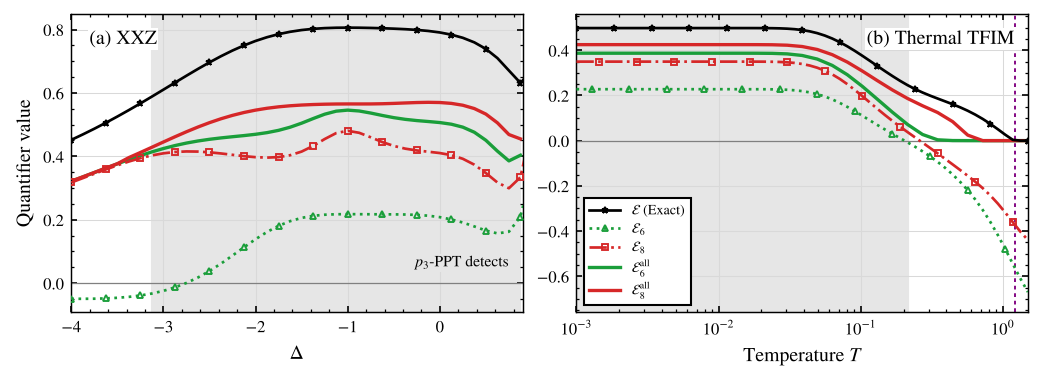

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.4))
ax = axes[0]
g = grids["XXZ"]
for j, k in ((0, "E"), (2, "E6"), (3, "E8")):
    plot_q(ax, g, scans["XXZ"][j], k, every=3, ms=3.0)
ax.plot(xxz_grid, xxz_all[6], color=COL["E6"], lw=1.6, label=r"$\mathcal{E}_6^{\rm all}$")
ax.plot(xxz_grid, xxz_all[8], color=COL["E8"], lw=1.6, label=r"$\mathcal{E}_8^{\rm all}$")
det = xxz_grid[xxz_p3]
ax.axvspan(det.min(), xxz_grid.max(), color="0.9", zorder=0)
ax.text(0.97, 0.14, r"$p_3$-PPT detects", transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5,
        bbox=dict(fc="0.9", ec="none", pad=0.6))
ax.axhline(0, color="gray", lw=0.6, zorder=1)
ax.set_xlabel(r"$\Delta$"); ax.set_ylabel("Quantifier value"); ax.set_xlim(-4, 0.9)
panel_label(ax, "(a) XXZ")
ax = axes[1]
for j, k in ((0, "E"), (2, "E6"), (3, "E8")):
    plot_q(ax, T_vals, thermal[j], k, every=(j, 5), ms=3.0)
ax.plot(T_all, th_all[6], color=COL["E6"], lw=1.6, label=r"$\mathcal{E}_6^{\rm all}$")
ax.plot(T_all, th_all[8], color=COL["E8"], lw=1.6, label=r"$\mathcal{E}_8^{\rm all}$")
ax.axvspan(T_vals[0], T_p3, color="0.9", zorder=0)
ax.axvline(T_sd, color="purple", lw=0.9, ls=(0, (2, 2)))
ax.axhline(0, color="gray", lw=0.6, zorder=1)
ax.set_xscale("log"); ax.set_xlim(T_vals[0], 1.5); ax.set_ylim(-0.76, 0.56)
ax.set_xlabel(r"Temperature $T$")
panel_label(ax, "(b) Thermal TFIM", x=0.97, ha="right")
ax.legend(loc="lower left", fontsize=6.8, ncol=1)
fig.tight_layout(pad=0.2, w_pad=0.8)
save(fig, "fig_sm_odd_moments"); plt.show()

## 11. Small windows (SM Sec. S9, Fig. S2)

Blocks $A$ and $B$ of two sites each in the middle of the $n=12$ chain, the
remaining eight sites traced out. The partial transpose is $16\times16$, so
moments up to $p_8$ are within reach of randomized measurements.

In [23]:
def spectrum_window(model, x, nAB):
    vals, psi = ground_state(HAM[model](N, x), PEN[model])
    c = (N - 2 * nAB) // 2
    lam = pt_spectrum_pure(psi, N, list(range(c, c + nAB)), list(range(c + nAB, c + 2 * nAB)))
    return lam[np.abs(lam) > 1e-12]

small = {}
for m, grid in (("TFIM", np.round(np.arange(0.05, 2.0001, 0.05), 3)),
                ("XXZ", np.round(np.arange(-4, 0.9001, 0.125), 3))):
    rows = []
    for x in grid:
        lam = spectrum_window(m, x, 2)
        rows.append(list(all_quantifiers(lam)) + [E_all(lam, 8)])
    small[m] = (grid, np.array(rows).T)
for m, x in (("TFIM", 0.85), ("TFIM", 1.5), ("XXZ", -0.5), ("XXZ", 0.5)):
    g, r = small[m]; j = np.argmin(abs(g - x))
    print(f"2+2 {m} {x}: E={r[0, j]:.3f}  E8={r[3, j]:.3f} ({r[3, j]/r[0, j]:.0%})  "
          f"E8_all={r[4, j]:.3f} ({r[4, j]/r[0, j]:.0%})")

2+2 TFIM 0.85: E=0.228  E8=0.092 (41%)  E8_all=0.200 (88%)
2+2 TFIM 1.5: E=0.283  E8=0.226 (80%)  E8_all=0.272 (96%)
2+2 XXZ -0.5: E=0.515  E8=0.367 (71%)  E8_all=0.466 (90%)
2+2 XXZ 0.5: E=0.398  E8=0.214 (54%)  E8_all=0.382 (96%)


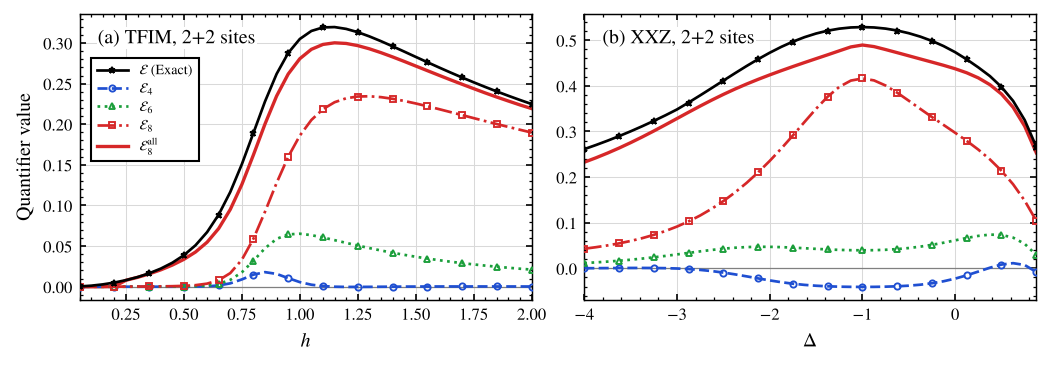

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.3))
for ax, m, xl, tag in ((axes[0], "TFIM", r"$h$", "(a) TFIM, 2+2 sites"),
                       (axes[1], "XXZ", r"$\Delta$", "(b) XXZ, 2+2 sites")):
    g, r = small[m]
    for j, k in enumerate(KEYS):
        plot_q(ax, g, r[j], k, every=3, ms=3.0)
    ax.plot(g, r[4], color=COL["E8"], lw=1.6, label=r"$\mathcal{E}_8^{\rm all}$")
    ax.axhline(0, color="gray", lw=0.6, zorder=1)
    ax.set_xlabel(xl); ax.set_xlim(g.min(), g.max())
    panel_label(ax, tag)
axes[0].set_ylabel("Quantifier value")
axes[0].legend(loc="upper left", bbox_to_anchor=(0.01, 0.87), fontsize=6.8)
fig.tight_layout(pad=0.2, w_pad=0.8)
save(fig, "fig_sm_small_window"); plt.show()

## 12. A certified bound at a stated confidence (SM Sec. S10, Fig. S3)

$\mathcal E_4=\tfrac12\ln(p_2^3/p_4)$ increases with $p_2$ and decreases with
$p_4$. If $p_2\ge p_2^{\rm lo}$ and $p_4\le p_4^{\rm hi}$ hold with
probability at least $1-\alpha/2$ each, then
$\mathcal E\ge\mathcal E_4\ge\tfrac12\ln[(p_2^{\rm lo})^3/p_4^{\rm hi}]$
with probability at least $1-\alpha$ (union bound). In the noise model of
Appendix C we use one-sided Gaussian intervals with the estimated widths
$\hat p_k/\sqrt{N_s}$, and check the coverage by simulation.

Werner coverage of the 95% bound: [0.998 0.997 0.995 0.994 0.993 0.994 0.992 0.995 0.992]
TFIM coverage of the 95% bound: [0.998 0.996 0.995 0.995 0.994 0.994 0.992 0.994 0.993]


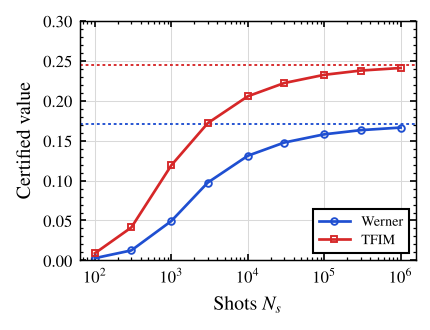

In [25]:
from scipy.stats import norm
alpha = 0.05
z = norm.ppf(1 - alpha / 2)
rng_c = np.random.default_rng(SEED + 1)
conf = {}
for name, lam in (("Werner", werner_spec(0.5)), ("TFIM", lam_tfim)):
    m = moments(lam, 2); E = exact_E(lam); E4 = E4_q(m[2], m[4])
    rec = dict(N=N_list, mean=[], coverage=[], E=E, E4=E4)
    for Ns in N_list:
        p2 = m[2] * (1 + rng_c.normal(size=n_trials) / np.sqrt(Ns))
        p4 = m[4] * (1 + rng_c.normal(size=n_trials) / np.sqrt(Ns))
        p2lo = p2 * (1 - z / np.sqrt(Ns)); p4hi = p4 * (1 + z / np.sqrt(Ns))
        cert = np.where(p2lo > 0, 1.5 * np.log(np.maximum(p2lo, 1e-300)) - 0.5 * np.log(p4hi), -np.inf)
        cert = np.maximum(cert, 0.0)                 # E >= 0 holds for every state
        rec["mean"].append(float(np.mean(cert)))
        rec["coverage"].append(float(np.mean(cert <= max(E4, 0.0) + 1e-15)))
    conf[name] = rec
    print(name, "coverage of the 95% bound:", np.round(rec["coverage"], 3))
    assert min(rec["coverage"]) >= 1 - alpha - 0.01
json.dump(conf, open(f"{FIGDIR}/confidence.json", "w"), indent=1)

fig, ax = plt.subplots(figsize=(2.72, 2.05))
for name, c, mk in (("Werner", COL["E4"], "o"), ("TFIM", COL["E8"], "s")):
    r = conf[name]
    ax.plot(r["N"], r["mean"], color=c, marker=mk, ms=3.2, markerfacecolor="none", label=name)
    ax.axhline(r["E4"], color=c, lw=0.9, ls=(0, (1.5, 1.5)))
ax.set_xscale("log"); ax.set_xlabel(r"Shots $N_s$"); ax.set_ylabel("Certified value")
ax.set_ylim(0, 0.3)
ax.legend(loc="lower right", fontsize=6.8)
fig.tight_layout(pad=0.2)
save(fig, "fig_sm_confidence"); plt.show()

## 13. Stabilizer states, pure and mixed (Corollary 1, SM Sec. S4)

Random stabilizer states from random Clifford circuits, with random qubits
traced out and a random bipartition of the rest. The nonzero magnitudes of
the PT spectrum are all equal, as proven in SM Sec. S4.

In [26]:
rng_s = np.random.default_rng(7)
Hd = np.array([[1, 1], [1, -1]]) / np.sqrt(2); Sd = np.diag([1, 1j])

def gate1(psi, U, q, n):
    psi = np.tensordot(U, psi.reshape([2] * n), axes=([1], [q]))
    return np.moveaxis(psi, 0, q).reshape(-1)

def cnot(psi, c, t, n):
    psi = psi.reshape([2] * n).copy(); idx = [slice(None)] * n; idx[c] = 1
    psi[tuple(idx)] = np.flip(psi[tuple(idx)], axis=t if t < c else t - 1)
    return psi.reshape(-1)

worst = 0.0
for trial in range(400):
    n = int(rng_s.integers(4, 9))
    psi = np.zeros(2**n, complex); psi[0] = 1
    for _ in range(int(rng_s.integers(10, 80))):
        g = rng_s.integers(3)
        if g == 2:
            c, t = rng_s.choice(n, 2, replace=False); psi = cnot(psi, c, t, n)
        else:
            psi = gate1(psi, (Hd, Sd)[g], int(rng_s.integers(n)), n)
    perm = rng_s.permutation(n); k = int(rng_s.integers(0, n - 1))
    keep, rest = sorted(perm[k:]), sorted(perm[:k]); nA = int(rng_s.integers(1, len(keep)))
    M = psi.reshape([2] * n).transpose(keep + rest).reshape(2**len(keep), -1)
    lam = pt_spectrum_rho(M @ M.conj().T, nA, len(keep) - nA)
    mags = np.abs(lam[np.abs(lam) > 1e-9])
    worst = max(worst, (mags.max() - mags.min()) / mags.max())
    q = all_quantifiers(lam); assert abs(q[1] - q[0]) < 1e-10
print(f"400 random stabilizer states (pure and mixed): max relative spread of |lambda| = {worst:.1e}, E_4 = E in all")

400 random stabilizer states (pure and mixed): max relative spread of |lambda| = 4.4e-15, E_4 = E in all


## 14. Every number quoted in the manuscript, checked

Each assertion compares a computed value with the value printed in the main
text, End Matter or SM (to the printed precision). A failing assertion means
the manuscript and the code disagree.

In [27]:
def close(x, y, tol):
    return abs(x - y) <= tol

wi = np.argmin(abs(p_vals - 0.5))
checks = {
    "Werner p=1/2: E4, E6, E8=E": close(werner[1, wi], 0.170, 5e-4) and close(werner[2, wi], 0.174, 5e-4)
                                   and close(werner[3, wi], 0.223, 5e-4) and close(werner[0, wi], 0.223, 5e-4),
    "TFIM h=0.85: 0.542, 0.245, 0.290, 0.380": all(close(quoted["TFIM h=0.85"][k], v, 5e-4)
        for k, v in zip(KEYS, (0.542, 0.245, 0.290, 0.380))),
    "TFIM h=2: E=0.238, E4=0.004, E8=0.195": all(close(quoted["TFIM h=2"][k], v, 5e-4)
        for k, v in zip(("E", "E4", "E8"), (0.238, 0.004, 0.195))),
    "TFIM h=0: all vanish": all(abs(v) < 5e-4 for v in quoted["TFIM h=0"].values()),
    "XXZ D=-4: E=0.452, E4=-0.061, E6=-0.049, E8=0.317": all(close(quoted["XXZ D=-4"][k], v, 5e-4)
        for k, v in zip(KEYS, (0.452, -0.061, -0.049, 0.317))),
    "XXZ D=-0.5: 0.803, 0.195, 0.217, 0.433": all(close(quoted["XXZ D=-0.5"][k], v, 5e-4)
        for k, v in zip(KEYS, (0.803, 0.195, 0.217, 0.433))),
    "LMG peak h ~ 0.71": close(h_lmg_peak, 0.71, 5e-3),
    "Sudden death T ~ 1.21": close(T_sd, 1.21, 5e-3),
    "Zero crossings 0.16, 0.20, 0.26": all(close(T_cross[k], v, 5e-3)
        for k, v in zip(("E4", "E6", "E8"), (0.16, 0.20, 0.26))),
    "s = 407, 638, 36": [mb_conv[m]["s"] for m in ("TFIM", "XXZ", "LMG")] == [407, 638, 36],
    "LMG exact at K = 4s = 144": mb_conv["LMG"]["K_exact"] == 144,
    "Noise gaps 0.049, 0.252": close(noise["Werner"]["gap"], 0.049, 5e-4) and close(noise["TFIM"]["gap"], 0.252, 5e-4),
    "Odd moments: TFIM h=0.85 E6_all=0.418, E8_all=0.444": close(table["TFIM 0.85"]["all6"], 0.418, 1e-3)
        and close(table["TFIM 0.85"]["all8"], 0.444, 1e-3),
    "Odd moments: XXZ D=-4 E6_all=0.321": close(table["XXZ -4.0"]["all6"], 0.321, 1e-3),
    "Thermal: all-moment bounds vanish at 0.28, 0.61, 0.71; p3-PPT at 0.21":
        all(close(T_cross_all[K], v, 5e-3) for K, v in ((4, 0.28), (6, 0.61), (8, 0.71))) and close(T_p3, 0.21, 5e-3),
    "DMRG converged up to n=32 (TFIM), n=36 (XXZ)":
        max(r["n"] for r in dmrg["TFIM"] if r["converged"]) == 32
        and max(r["n"] for r in dmrg["XXZ"] if r["converged"]) == 36,
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
for m in ("TFIM", "XXZ"):
    d = mb_conv[m]
    print(f"{m}: gap at K=160 is {d['E'] - d['EK'][d['K'].index(160)]:.1e}")
assert all(checks.values())
import platform, scipy
print("python", platform.python_version(), "numpy", np.__version__, "scipy", scipy.__version__,
      "mpmath", mp.__version__, "matplotlib", matplotlib.__version__, "quimb", qu.__version__)

PASS  Werner p=1/2: E4, E6, E8=E
PASS  TFIM h=0.85: 0.542, 0.245, 0.290, 0.380
PASS  TFIM h=2: E=0.238, E4=0.004, E8=0.195
PASS  TFIM h=0: all vanish
PASS  XXZ D=-4: E=0.452, E4=-0.061, E6=-0.049, E8=0.317
PASS  XXZ D=-0.5: 0.803, 0.195, 0.217, 0.433
PASS  LMG peak h ~ 0.71
PASS  Sudden death T ~ 1.21
PASS  Zero crossings 0.16, 0.20, 0.26
PASS  s = 407, 638, 36
PASS  LMG exact at K = 4s = 144
PASS  Noise gaps 0.049, 0.252
PASS  Odd moments: TFIM h=0.85 E6_all=0.418, E8_all=0.444
PASS  Odd moments: XXZ D=-4 E6_all=0.321
PASS  Thermal: all-moment bounds vanish at 0.28, 0.61, 0.71; p3-PPT at 0.21
PASS  DMRG converged up to n=32 (TFIM), n=36 (XXZ)
TFIM: gap at K=160 is 9.6e-05
XXZ: gap at K=160 is 8.2e-03
python 3.13.18 numpy 2.5.3 scipy 1.18.1 mpmath 1.3.0 matplotlib 3.11.2 quimb 1.16.0
